<a href="https://colab.research.google.com/github/JulienRequa/exoplanet-search/blob/main/pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exoplanet Pipeline
Clean, reusable version of the transit-search pipeline developed in lab_notebook.ipynb.
Run any star: analyze_star("STAR NAME")

### To-do
- [x] Trim before gaps (added; 0.25 d). Day-1394 patch = transit at the segment edge +
      smoother edge effect in the unmasked pass, not a spacecraft glitch. Check the masked version.
      → Confirmed: the masked clean fixes it
- [x] Boundary flags in fit_transit
- [x] Vetting: odd/even depths
- [ ] Per-transit depth check (flag single transits that don't match)
- [x] Automatic profile scan when b is flagged (upper limit, like lab notebook)
- [x] Print flags once (quiet fit_transit, summary in analyze_star)
- [x] Vetting: secondary eclipse
- [ ] Secondary: mask eclipse during flattening; fit a local sloped baseline
      (or model the phase curve: ellipsoidal variation + planet glow)
- [ ] Bonus: planet dayside temperature from eclipse depth
- [x] Planet size check (catches star-sized companions, incl. identical twins)
- [x] Vetting: density check
- [ ] vet=True option in analyze_star (measure + vet in one call)
- [ ] Cleanup pass: remove scratch cells, add Development notes, then pipeline.py

In [1]:
!pip install lightkurve batman-package -q

import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import batman
from scipy.optimize import curve_fit

G = 6.674e-11   # gravitational constant (SI)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
def download(star_name, n_sectors=1):
    """Download up to n_sectors of TESS 2-minute SPOC light curves for a star.
    Always returns a LIST of light curves (one per sector).
    """
    search = lk.search_lightcurve(star_name, mission="TESS",
                                  author="SPOC", exptime=120)
    if len(search) == 0:                                   # no data → stop with a clear message
        raise ValueError(f"No TESS 2-minute data found for {star_name}")
    return list(search[:n_sectors].download_all())

# Test
lcs = download("WASP-18", n_sectors=2)
print("Sectors downloaded:", len(lcs))
for lc in lcs:
    print("Sector", lc.sector, "→", len(lc), "points")

Sectors downloaded: 2
Sector 2 → 18299 points
Sector 3 → 13541 points


## Cleaning
clean() handles one sector (remove NaNs, trim the post-gap ramp, remove high outliers,
flatten with optional transit mask). clean_all() cleans each sector separately, then joins them.

Total points after cleaning: 29725


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

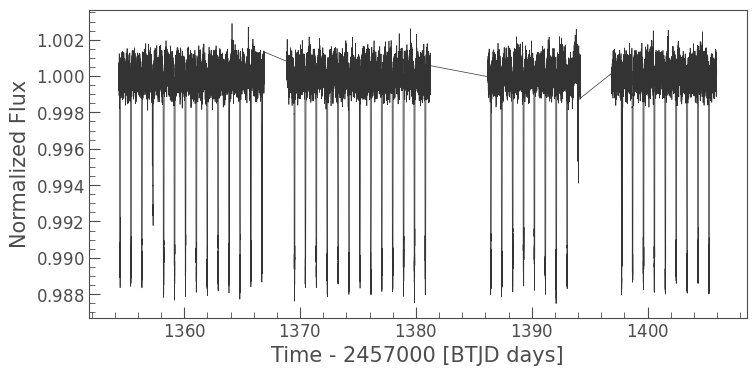

In [21]:
def plain(x):
    """Turn an astropy/lightkurve value (units or hidden masks) into a plain number."""
    return float(np.asarray(getattr(x, "value", x)))

def clean(lc, window_length=721, period=None, t0=None, duration=None, trim=0.25):
    """Clean ONE sector: remove NaNs, trim the ramp after data gaps, remove high
    outliers, and flatten. If period/t0/duration are given, transits are masked
    while flattening.
    """
    lc = lc.remove_nans()
    lc = lk.LightCurve(time=lc.time,
                       flux=np.asarray(lc.flux.value),
                       flux_err=np.asarray(lc.flux_err.value))

    t = np.asarray(lc.time.value, dtype=float)
    restarts = np.r_[t[0], t[1:][np.diff(t) > 0.5]]     # sector start + after each gap
    stops = np.r_[t[:-1][np.diff(t) > 0.5], t[-1]]      # NEW: before each gap + sector end
    keep = np.ones(len(t), dtype=bool)
    for start in restarts:
        keep &= ~((t >= start) & (t < start + trim))
    for stop in stops:                                  # NEW: cut the last `trim` days
        keep &= ~((t <= stop) & (t > stop - trim))      #      before each gap
    lc = lc[keep]

    lc = lc.remove_outliers(sigma_upper=4, sigma_lower=float("inf"))
    if period is None:
        mask = None
    else:
        P, T0, D = plain(period), plain(t0), plain(duration)
        t = np.asarray(lc.time.value, dtype=float)
        phase = (t - T0 + 0.5 * P) % P - 0.5 * P
        mask = np.abs(phase) < 0.75 * D
    return lc.flatten(window_length=window_length, mask=mask)

def clean_all(lcs, period=None, t0=None, duration=None):
    """Clean each sector separately, then join them into one light curve."""
    cleaned = [clean(lc, period=period, t0=t0, duration=duration) for lc in lcs]
    return lk.LightCurveCollection(cleaned).stitch()

# Test
combined = clean_all(lcs)
print("Total points after cleaning:", len(combined))
combined.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

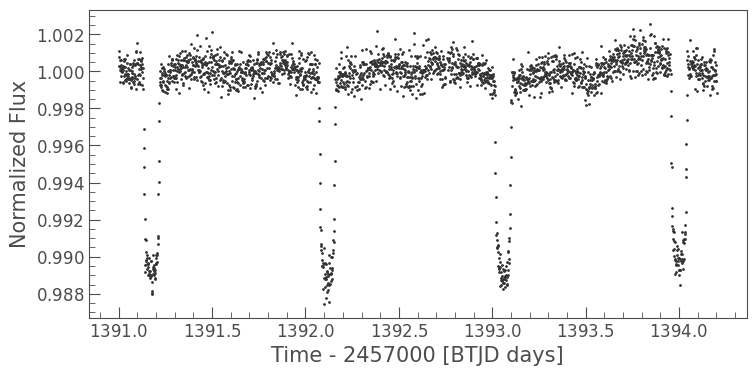

In [22]:
masked = clean_all(lcs, period=popt1[1], t0=popt1[0], duration=duration)
zoom = (masked.time.value > 1391) & (masked.time.value < 1395)
masked[zoom].scatter()

**Test:** WASP-18, sectors 2 + 3 → 30,443 points after cleaning; both sectors flattened to 1.0.
Each sector is cleaned separately because each has its own brightness level and drifts,
and smoothing across the gap between sectors would invent a fake trend.
To-do: messy patch near day 1394 just BEFORE a data gap → consider trimming before gaps too.

## Period search
Box Least Squares (BLS). Quiet by default (plot=False). The longest period searched is
capped at half the data's time span, so any detected signal repeats at least twice.

Period: 0.941794179417942 d  Duration: 0.08 d  Depth: 0.009530574506378007


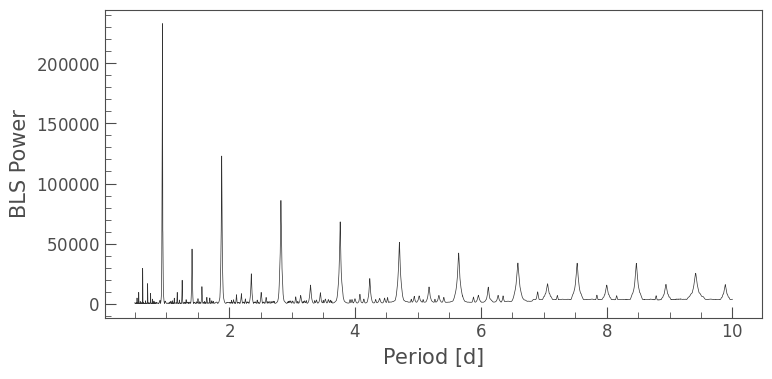

In [4]:
def search(lc, min_period=0.5, max_period=10, n_periods=10000, plot=False):
    """Search one light curve for repeating box-shaped dips (BLS).
    Returns: period, transit time (t0), duration, depth of the strongest signal.
    """
    t = np.asarray(lc.time.value, dtype=float)
    span = t.max() - t.min()                       # how many days the data covers
    if max_period > span / 2:                      # need at least 2 transits
        max_period = span / 2

    periods = np.linspace(min_period, max_period, n_periods)
    pg = lc.to_periodogram(method="bls", period=periods,
                           duration=[0.05, 0.08, 0.1, 0.15, 0.2])
    if plot:
        pg.plot()
    return (pg.period_at_max_power, pg.transit_time_at_max_power,
            pg.duration_at_max_power, pg.depth_at_max_power)

# Test on ONE cleaned sector
first = clean(lcs[0])
period, t0, duration, depth = search(first, plot=True)
print("Period:", period, " Duration:", duration, " Depth:", depth)

## Transit model and fit
Limb-darkened batman model with impact parameter b. fit_transit flags any parameter at
its boundary (its ± is then unreliable → report a limit instead). Multi-sector fits start
from a single-sector answer so the period doesn't drift across long time gaps.

In [5]:
PARAM_NAMES = ["t0", "period", "Rp/Rs", "a/Rs", "b", "u1", "u2"]

def transit_model(t, t0, per, rp, a, b, u1, u2):
    """Limb-darkened transit light curve (batman).
    b = impact parameter (0 = crosses star's center); inclination is computed from b.
    """
    params = batman.TransitParams()
    params.t0, params.per, params.rp, params.a = t0, per, rp, a
    params.inc = np.degrees(np.arccos(np.clip(b / a, 0, 1)))
    params.ecc, params.w = 0.0, 90.0                     # circular orbit
    params.u, params.limb_dark = [u1, u2], "quadratic"
    return batman.TransitModel(params, t).light_curve(params)

def plot_fit(t, f, popt):
    """Folded data + model (top) and residuals (bottom)."""
    xph = (t - popt[0] + 0.5 * popt[1]) % popt[1] - 0.5 * popt[1]
    model = transit_model(t, *popt)
    order = np.argsort(xph)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})
    ax1.plot(xph, f, ".", ms=2, alpha=0.4, label="TESS data")
    ax1.plot(xph[order], model[order], "r-", lw=2, label="model")
    ax1.set_ylabel("Normalized flux"); ax1.legend()
    ax2.plot(xph, f - model, ".", ms=2, alpha=0.4)
    ax2.axhline(0, color="r")
    ax2.set_xlabel("Days from transit center"); ax2.set_ylabel("Data − model")
    plt.show()

In [16]:
def fit_transit(lc, period, t0, duration, depth, start=None, plot=False, verbose=False):
    """Fit the transit model. If `start` (a previous best fit) is given, begin there
    with tighter timing bounds (needed for multi-sector data).
    Returns: popt, errs, inc, inc_err, flags
    """
    P0, T00, D = plain(period), plain(t0), plain(duration)
    if start is not None:                                # use refined timing to pick points
        T00, P0 = start[0], start[1]
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    ph = (t - T00 + 0.5 * P0) % P0 - 0.5 * P0
    near = np.abs(ph) < max(2 * D, 0.1)                  # only points near transits
    t, f = t[near], f[near]

    if start is None:                                    # first fit: guesses from physics
        guess = [T00, P0, np.sqrt(max(plain(depth), 1e-5)),
                 4.2 * P0 ** (2 / 3), 0.3, 0.3, 0.2]
        dt, dP = 0.02, 0.002
    else:                                                # refine from a previous answer
        guess, dt, dP = list(start), 0.01, 0.0001
    bounds = ([guess[0] - dt, guess[1] - dP, 0.01, 1.5,   0.0, 0.0, -0.5],
              [guess[0] + dt, guess[1] + dP, 0.30, 100.0, 1.2, 1.0,  1.0])

    popt, pcov = curve_fit(transit_model, t, f, p0=guess, bounds=bounds)
    errs = np.sqrt(np.diag(pcov))

    # Inclination from b and a/Rs, with error propagation
    a_fit, b_fit = popt[3], popt[4]
    s = np.sqrt(1 - (b_fit / a_fit) ** 2)
    inc = np.degrees(np.arccos(b_fit / a_fit))
    J = np.array([b_fit / (a_fit**2 * s), -1 / (a_fit * s)])
    inc_err = np.degrees(np.sqrt(J @ pcov[3:5, 3:5] @ J))

    # Boundary flags: value near a limit, OR its error bar reaches past a limit
    flags = []
    for name, val, err, lo, hi in zip(PARAM_NAMES, popt, errs, bounds[0], bounds[1]):
        width = hi - lo
        if val - lo < max(0.01 * width, err) or hi - val < max(0.01 * width, err):
            flags.append(name)
    if flags and verbose:
        print("⚠️ At a boundary (± unreliable → report a limit):", flags)

    if plot:
        plot_fit(t, f, popt)
    return popt, errs, inc, inc_err, flags

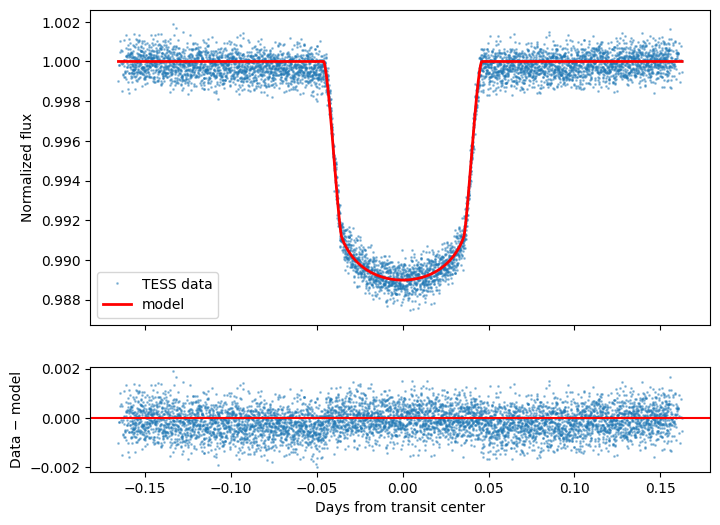

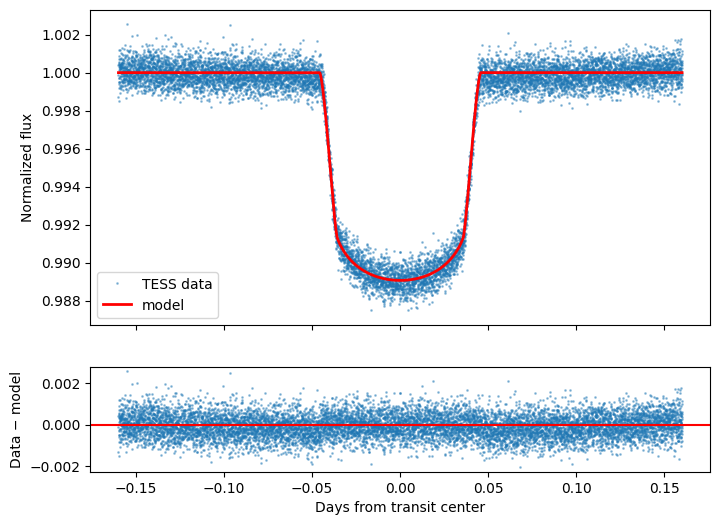

t0      1 sector: 1354.45779 ± 0.00006   2 sectors: 1354.45786 ± 0.00004
period  1 sector: 0.94146 ± 0.00000   2 sectors: 0.94145 ± 0.00000
Rp/Rs   1 sector: 0.09998 ± 0.00033   2 sectors: 0.09925 ± 0.00025
a/Rs    1 sector: 3.35853 ± 0.02667   2 sectors: 3.42212 ± 0.02187
b       1 sector: 0.44254 ± 0.01840   2 sectors: 0.40578 ± 0.01651
u1      1 sector: 0.29618 ± 0.04803   2 sectors: 0.30438 ± 0.03380
u2      1 sector: 0.14495 ± 0.08317   2 sectors: 0.13836 ± 0.06027
inc     1 sector: 82.43 ± 0.38   2 sectors: 83.19 ± 0.32


In [17]:
# 1) Single sector, masked clean, first fit
c1 = clean(lcs[0], period=period, t0=t0, duration=duration)
popt1, errs1, inc1, inc_err1, flags1 = fit_transit(c1, period, t0, duration, depth, plot=True)

# 2) Both sectors, starting from the 1-sector answer
c2 = clean_all(lcs, period=period, t0=t0, duration=duration)
popt2, errs2, inc2, inc_err2, flags2 = fit_transit(c2, period, t0, duration, depth,
                                                    start=popt1, plot=True)

for name, v1, e1, v2, e2 in zip(PARAM_NAMES, popt1, errs1, popt2, errs2):
    print(f"{name:7s} 1 sector: {v1:.5f} ± {e1:.5f}   2 sectors: {v2:.5f} ± {e2:.5f}")
print(f"inc     1 sector: {inc1:.2f} ± {inc_err1:.2f}   2 sectors: {inc2:.2f} ± {inc_err2:.2f}")

In [34]:
import io, contextlib

R_JUP = 0.10045   # Jupiter's radius in solar radii

def vet_star(results, verbose=True):
    """Run all vetting checks on an analyze_star result and print a one-screen report."""
    lc, popt = results["lc"], get_popt(results)

    with contextlib.redirect_stdout(io.StringIO()):       # run the checks without their printouts
        _, _, oe_sigma = odd_even(lc, popt)
        sec_depth, sec_err, sec_sigma, sec_ratio = secondary_eclipse(lc, popt)
        dens = density_check(results)

    # Detection strength: how many times bigger the dip is than the noise
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    model = transit_model(t, *popt)
    in_tr = model < 1
    depth = 1 - model.min()
    snr = depth / (np.std(f[~in_tr]) / np.sqrt(in_tr.sum()))

    # Planet size in Jupiter radii
    R = results["star_info"].get("RADIUS")
    rp_jup = popt[2] * float(R) / R_JUP if R else None

    checks = [("Detection SNR", "PASS" if snr > 7.1 else "FAIL", f"SNR = {snr:.0f}"),
              ("Odd/even depths", "PASS" if oe_sigma < 3 else "FAIL", f"{oe_sigma:.1f}σ difference"),
              ("Secondary eclipse", "FAIL" if (sec_sigma > 3 and sec_ratio > 0.1) else "PASS",
               f"{sec_depth*1e6:.0f} ± {sec_err*1e6:.0f} ppm ({sec_ratio*100:.1f}% of transit)")]
    if dens is None:
        checks.append(("Density", "N/A", "no catalog data"))
    else:
        checks.append(("Density", "PASS" if 0.5 < dens[1] < 2 else "FAIL",
                       f"transit / catalog = {dens[1]:.2f}"))
    if rp_jup is None:
        checks.append(("Planet size", "N/A", "no stellar radius"))
    else:
        checks.append(("Planet size", "PASS" if rp_jup < 2.5 else "FAIL",
                       f"Rp = {rp_jup:.2f} R_Jup"))

    statuses = [c[1] for c in checks]
    n_run = sum(s != "N/A" for s in statuses)
    n_pass = statuses.count("PASS")
    if "FAIL" in statuses:
        verdict = "LIKELY FALSE POSITIVE"
    elif n_pass < len(checks):
        verdict = "PLANET CANDIDATE (some checks not run)"
    else:
        verdict = "PLANET CANDIDATE"

    if verbose:
        print(f"\n===== {results['star']}: VETTING REPORT =====")
        print(f"Period = {popt[1]:.5f} d | Rp/R★ = {popt[2]:.4f} | depth = {depth*100:.2f}%")
        for name, status, detail in checks:
            print(f"  {name:18s} {status:5s} {detail}")
        if results["flags"]:
            print(f"  Fit note: {results['flags']} at a boundary", end="")
            if "b_upper" in results:
                print(f" → b < {results['b_upper']:.2f}, inc > {results['inc_lower']:.1f}°", end="")
            print()
        print(f"VERDICT: {verdict} ({n_pass}/{n_run} checks passed)")

    report = {"checks": checks, "snr": snr, "rp_jup": rp_jup, "verdict": verdict,
              "n_pass": n_pass, "n_run": n_run}
    results["vetting"] = report
    return report

_ = vet_star(w18)
_ = vet_star(w121)


===== WASP-18: VETTING REPORT =====
Period = 0.94145 d | Rp/R★ = 0.0992 | depth = 1.09%
  Detection SNR      PASS  SNR = 1404
  Odd/even depths    PASS  0.1σ difference
  Secondary eclipse  PASS  487 ± 9 ppm (4.4% of transit)
  Density            PASS  transit / catalog = 1.23
  Planet size        PASS  Rp = 1.33 R_Jup
VERDICT: PLANET CANDIDATE (5/5 checks passed)

===== WASP-121: VETTING REPORT =====
Period = 1.27492 d | Rp/R★ = 0.1208 | depth = 1.65%
  Detection SNR      PASS  SNR = 827
  Odd/even depths    PASS  0.1σ difference
  Secondary eclipse  PASS  379 ± 25 ppm (2.3% of transit)
  Density            PASS  transit / catalog = 1.13
  Planet size        PASS  Rp = 1.83 R_Jup
  Fit note: ['b'] at a boundary → b < 0.19, inc > 87.1°
VERDICT: PLANET CANDIDATE (5/5 checks passed)


In [35]:
def profile_b(lc, popt, b_max=0.8, n=17, plot=False):
    """95% upper limit on impact parameter b, by profile scan.
    Fix b on a grid, refit everything else, and track how much χ² worsens.
    Use when b is stuck near 0 (nearly edge-on). Returns (b_upper, inc_lower).
    """
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    P, T0 = popt[1], popt[0]
    near = np.abs((t - T0 + 0.5 * P) % P - 0.5 * P) < 0.2
    t, f = t[near], f[near]
    sigma = np.std(f - transit_model(t, *popt))            # noise per point

    b_grid = np.linspace(0, b_max, n)
    chi2 = []
    for bb in b_grid:
        def model_fixed_b(t, t0, per, rp, a, u1, u2):      # same model, b locked at bb
            return transit_model(t, t0, per, rp, a, bb, u1, u2)
        start = [popt[0], popt[1], popt[2], popt[3], popt[5], popt[6]]
        lo = [popt[0] - 0.01, popt[1] - 0.0001, 0.01, 1.5,   0.0, -0.5]
        hi = [popt[0] + 0.01, popt[1] + 0.0001, 0.30, 100.0, 1.0,  1.0]
        pf, _ = curve_fit(model_fixed_b, t, f, p0=start, bounds=(lo, hi))
        chi2.append(np.sum((f - model_fixed_b(t, *pf))**2) / sigma**2)

    dchi2 = np.array(chi2) - min(chi2)
    b_upper = np.interp(4, dchi2, b_grid)                  # where Δχ² crosses 4 (~95%)
    inc_lower = np.degrees(np.arccos(b_upper / popt[3]))

    if plot:
        plt.figure()
        plt.plot(b_grid, dchi2, "o-")
        plt.axhline(4, ls="--", color="red", label="Δχ² = 4 (~95%)")
        plt.xlabel("Impact parameter b (fixed)"); plt.ylabel("Δχ²"); plt.legend()
        plt.show()
    return b_upper, inc_lower

## Full pipeline: analyze_star
download → search one sector → fit one sector → (if more sectors) clean all with
refined timing and refit starting from the 1-sector answer. Returns a results dictionary,
including the cleaned light curve and any boundary flags.

In [36]:
def analyze_star(star_name, n_sectors=1, plot=False, verbose=True, vet=False):
    """Run the full pipeline on a star. Returns a dictionary of results."""
    lcs = download(star_name, n_sectors)
    star_info = {k: lcs[0].meta.get(k) for k in ["TEFF", "LOGG", "RADIUS"]}   # catalog values

    # Search and first fit on ONE sector
    period, t0, duration, depth = search(clean(lcs[0]), plot=plot)
    c1 = clean(lcs[0], period=period, t0=t0, duration=duration)
    popt, errs, inc, inc_err, flags = fit_transit(c1, period, t0, duration, depth,
                                                  plot=plot and len(lcs) == 1)
    cleaned = c1

    # Refine with all sectors, using the refined timing
    if len(lcs) > 1:
        cleaned = clean_all(lcs, period=popt[1], t0=popt[0], duration=duration)
        popt, errs, inc, inc_err, flags = fit_transit(cleaned, period, t0, duration,
                                                      depth, start=popt, plot=plot)

    rho = 3 * np.pi / (G * (popt[1] * 86400)**2) * popt[3]**3 / 1000
    results = {"star": star_name, "n_sectors": len(lcs), "flags": flags,
               "inc": (inc, inc_err), "density": (rho, rho * 3 * errs[3] / popt[3]),
               "lc": cleaned, "star_info": star_info}
    for name, val, err in zip(PARAM_NAMES, popt, errs):
        results[name] = (val, err)

    # Automatic upper limit when b is stuck near 0 (nearly edge-on)
    if "b" in flags and popt[4] < 0.5:
        results["b_upper"], results["inc_lower"] = profile_b(cleaned, popt, plot=plot)

    if verbose:
        print(f"=== {star_name} ({len(lcs)} sector(s)) ===")
        for name in PARAM_NAMES:
            v, e = results[name]
            print(f"{name:7s} = {v:.5f} ± {e:.5f}")
        print(f"inc     = {inc:.2f} ± {inc_err:.2f} deg")
        print(f"density = {rho:.2f} ± {results['density'][1]:.2f} g/cm³")
        if flags:
            print("⚠️ Flags:", flags)
        if "b_upper" in results:
            print(f"→ b < {results['b_upper']:.2f} (95%), so inc > {results['inc_lower']:.1f}°")
        if vet:
            vet_star(results, verbose=verbose)
    return results

=== WASP-18 (4 sector(s)) ===
t0      = 1354.45791 ± 0.00003
period  = 0.94145 ± 0.00000
Rp/Rs   = 0.09923 ± 0.00018
a/Rs    = 3.41760 ± 0.01609
b       = 0.40643 ± 0.01215
u1      = 0.29049 ± 0.02436
u2      = 0.17145 ± 0.04382
inc     = 83.17 ± 0.24 deg
density = 0.85 ± 0.01 g/cm³


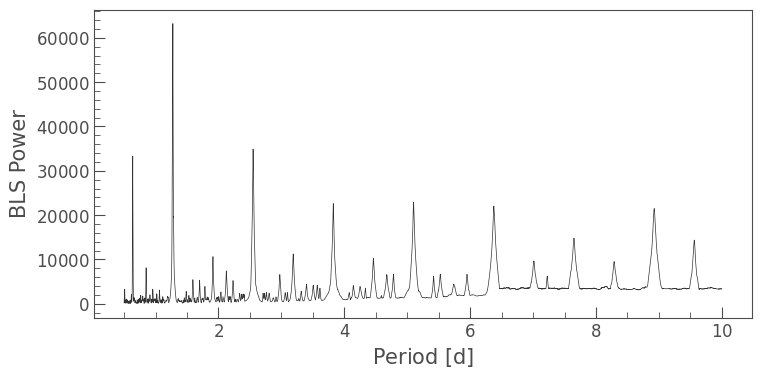

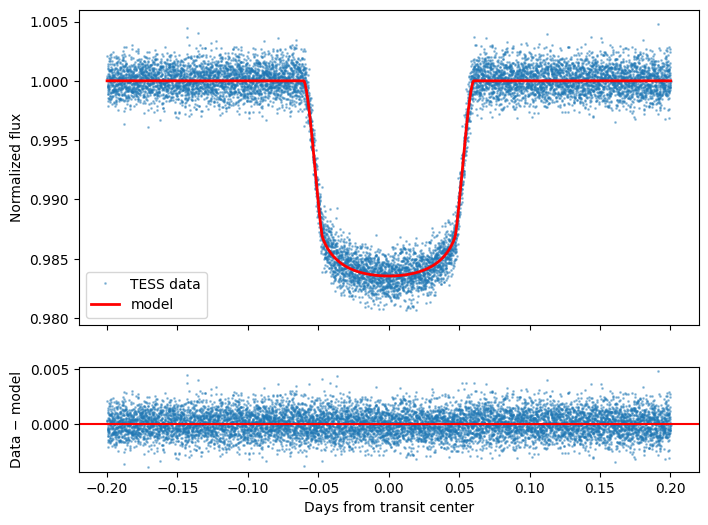

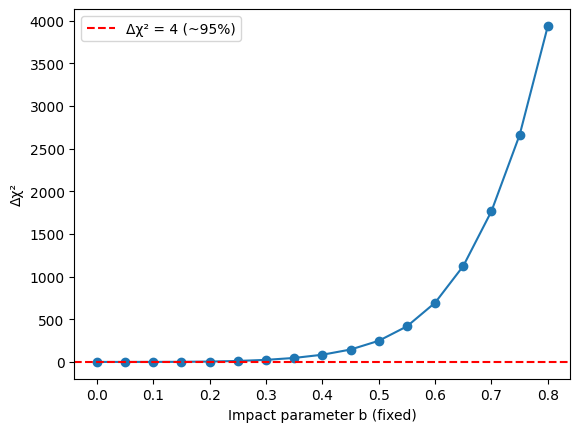

=== WASP-121 (2 sector(s)) ===
t0      = 1491.99873 ± 0.00006
period  = 1.27492 ± 0.00000
Rp/Rs   = 0.12077 ± 0.00040
a/Rs    = 3.82789 ± 0.03101
b       = 0.02360 ± 0.42336
u1      = 0.22103 ± 0.02866
u2      = 0.24368 ± 0.06552
inc     = 89.65 ± 6.34 deg
density = 0.65 ± 0.02 g/cm³
⚠️ Flags: ['b']
→ b < 0.19 (95%), so inc > 87.1°


In [29]:
w18 = analyze_star("WASP-18", n_sectors=4)
w121 = analyze_star("WASP-121", n_sectors=2, plot=True)

**Tests passed:**
- WASP-18 (4 sectors): reproduces my best hand analysis exactly (a/R★ = 3.421, inc = 83.20°,
  ρ★ = 0.85 g/cm³), no flags
- WASP-121 (2 sectors): Rp/R★ = 0.1208 ± 0.0004, automatically flagged b (0.018 ± 0.547)
  → nearly edge-on; report an upper limit (profile scan)

**Test:** WASP-121 (2 sectors): b flagged → automatic profile scan → b < 0.19 (95%),
inc > 87.2°. Tighter than 1 sector (b < 0.22) because more transits rule out larger b.
WASP-18: no flags, no scan.

## Vetting checks
### Odd/even depths
Number each transit; compare the average depth of odd- vs even-numbered transits.
Same depth (difference < 3σ) → consistent with a planet. Different → likely an eclipsing binary.

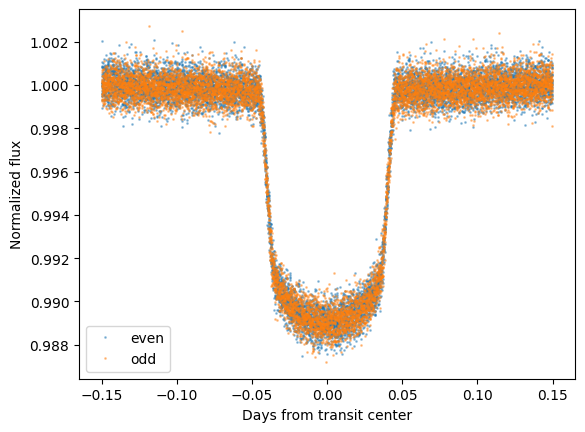

Even depth = 0.01038 ± 0.00002
Odd depth  = 0.01038 ± 0.00002
Difference = 0.1σ → OK, planet-like


In [38]:
def get_popt(results):
    """Pull the best-fit parameter list back out of an analyze_star results dictionary."""
    return [results[name][0] for name in PARAM_NAMES]

def odd_even(lc, popt, plot=False):
    """Compare depths of odd- vs even-numbered transits.
    Returns (depth_odd, depth_even, difference in σ).
    """
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    t0, P = popt[0], popt[1]
    n = np.round((t - t0) / P)                  # which transit each point belongs to
    phase = t - (t0 + n * P)                    # days from that transit's center

    model = transit_model(t, *popt)
    core = model < 1 - 0.8 * (1 - model.min())  # deepest part of each transit

    depths, errs = [], []
    for parity in [0, 1]:                       # 0 = even transits, 1 = odd transits
        pts = f[core & (n % 2 == parity)]
        depths.append(1 - np.mean(pts))
        errs.append(np.std(pts) / np.sqrt(len(pts)))
    sigma = abs(depths[0] - depths[1]) / np.sqrt(errs[0]**2 + errs[1]**2)

    if plot:
        near = np.abs(phase) < 0.15
        for parity, label in [(0, "even"), (1, "odd")]:
            sel = near & (n % 2 == parity)
            plt.plot(phase[sel], f[sel], ".", ms=2, alpha=0.4, label=label)
        plt.xlabel("Days from transit center"); plt.ylabel("Normalized flux")
        plt.legend(); plt.show()

    print(f"Even depth = {depths[0]:.5f} ± {errs[0]:.5f}")
    print(f"Odd depth  = {depths[1]:.5f} ± {errs[1]:.5f}")
    print(f"Difference = {sigma:.1f}σ → " + ("OK, planet-like" if sigma < 3 else "⚠️ suspicious"))
    return depths[1], depths[0], sigma

# Test on WASP-18 (4 sectors)
_ = odd_even(w18["lc"], get_popt(w18), plot=True)

**Test (WASP-18, 4 sectors):** even depth 0.01037, odd depth 0.01034 → 1.3σ difference
→ planet-like. A few odd-transit points sit high inside the dip (one glitchy transit?) →
to-do: per-transit depth check.

### Secondary eclipse
Look half an orbit after each transit. A large second dip → the companion shines →
likely an eclipsing binary. No dip (or a tiny one) → planet-like. A tiny, significant dip
can be the planet's own heat glow (hot Jupiters).

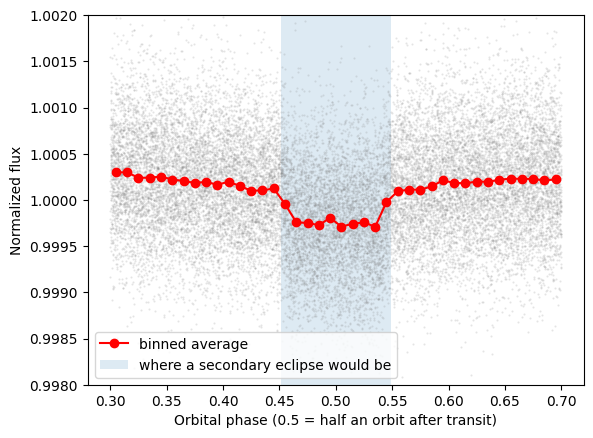

Secondary depth = 487 ± 9 ppm (52.5σ), 4.4% of transit depth
Small secondary detected → planet's own light? Planet-like


In [39]:
def secondary_eclipse(lc, popt, plot=False):
    """Look for a dip half an orbit after transit (assumes a circular orbit).
    Returns (depth, error, sigma, ratio to the transit depth).
    """
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    t0, P = popt[0], popt[1]
    phase = ((t - t0) / P) % 1                 # 0 = transit, 0.5 = half an orbit later

    # Transit duration (as a fraction of the orbit), from the fitted model
    grid = np.linspace(t0 - 0.5 * P, t0 + 0.5 * P, 5000)
    dur = np.mean(transit_model(grid, *popt) < 1)

    win = np.abs(phase - 0.5) < 0.4 * dur                       # core of where an eclipse would be
    base = (np.abs(phase - 0.5) > dur) & (np.abs(phase - 0.5) < 0.25)   # nearby, outside it
    depth = np.mean(f[base]) - np.mean(f[win])
    err = np.sqrt(np.var(f[win]) / win.sum() + np.var(f[base]) / base.sum())
    sigma = depth / err
    primary = 1 - transit_model(np.array([t0]), *popt)[0]       # transit depth at center
    ratio = depth / primary

    if plot:
        sel = np.abs(phase - 0.5) < 0.2
        bins = np.linspace(0.3, 0.7, 41)
        centers = 0.5 * (bins[1:] + bins[:-1])
        binned = [np.mean(f[sel][(phase[sel] >= lo) & (phase[sel] < hi)])
                  for lo, hi in zip(bins[:-1], bins[1:])]
        plt.plot(phase[sel], f[sel], ".", ms=1, alpha=0.2, color="gray")
        plt.plot(centers, binned, "o-", color="red", label="binned average")
        plt.axvspan(0.5 - 0.5 * dur, 0.5 + 0.5 * dur, alpha=0.15,
                    label="where a secondary eclipse would be")
        plt.ylim(0.998, 1.002)
        plt.xlabel("Orbital phase (0.5 = half an orbit after transit)")
        plt.ylabel("Normalized flux"); plt.legend(); plt.show()

    print(f"Secondary depth = {depth*1e6:.0f} ± {err*1e6:.0f} ppm ({sigma:.1f}σ), "
          f"{ratio*100:.1f}% of transit depth")
    if sigma > 3 and ratio > 0.1:
        print("⚠️ Large secondary eclipse → likely eclipsing binary")
    elif sigma > 3:
        print("Small secondary detected → planet's own light? Planet-like")
    else:
        print("No secondary detected → planet-like")
    return depth, err, sigma, ratio

_ = secondary_eclipse(w18["lc"], get_popt(w18), plot=True)

**Test (WASP-18, 4 sectors):** secondary eclipse detected: 480 ± 9 ppm (52σ),
4.4% of transit depth → planet's dayside thermal emission, not a stellar companion.
⚠️ Likely overestimated vs published TESS analyses (~350 ppm): baseline sags toward
phase 0.5 (ellipsoidal variation: the massive planet stretches its star, minima at
phase 0 and 0.5) and the smoother wasn't masking the eclipse. ±9 ppm is random error only.

### Density check
Compare stellar density from the transit (Kepler's 3rd law) with density from the
star's catalog surface gravity and radius: ρ★ = 3g / (4πGR).
Within a factor of 2 → consistent. Way off → the signal may come from a different star.

In [40]:
def density_check(results):
    """Compare transit-derived stellar density with the catalog value (log g + radius)."""
    info = results.get("star_info", {})
    logg, R = info.get("LOGG"), info.get("RADIUS")
    if logg is None or R is None:
        print("No catalog log g / radius → can't run the density check")
        return None
    g = 10 ** float(logg)                                     # surface gravity, cm/s²
    rho_cat = 3 * g / (4 * np.pi * 6.674e-8 * float(R) * 6.957e10)   # g/cm³ (CGS units)
    rho_fit = results["density"][0]
    ratio = rho_fit / rho_cat

    print(f"Catalog: log g = {float(logg):.2f}, R = {float(R):.2f} R☉ → ρ★ = {rho_cat:.2f} g/cm³")
    print(f"Transit: ρ★ = {rho_fit:.2f} g/cm³ → ratio = {ratio:.2f}")
    if 0.5 < ratio < 2:
        print("Consistent → planet-like")
    else:
        print("⚠️ Densities disagree → signal may not come from this star")
    return rho_cat, ratio

_ = density_check(w18)
_ = density_check(w121)

Catalog: log g = 4.26, R = 1.35 R☉ → ρ★ = 0.69 g/cm³
Transit: ρ★ = 0.85 g/cm³ → ratio = 1.23
Consistent → planet-like
Catalog: log g = 4.23, R = 1.52 R☉ → ρ★ = 0.58 g/cm³
Transit: ρ★ = 0.65 g/cm³ → ratio = 1.13
Consistent → planet-like


**Tests:** WASP-18: catalog 0.69 vs transit 0.85 g/cm³ (ratio 1.23); WASP-121: 0.58 vs 0.65
(ratio 1.13) → both consistent. Independent methods (spectrum log g vs Kepler's law) agree.

## Vetting report
vet_star() runs every check silently and prints one report card: detection strength (SNR),
odd/even depths, secondary eclipse, density consistency, and planet size.
Verdict: any FAIL → likely false positive; all pass → planet candidate.
(Pass/fail counts, not a probability.)

**Tests:** WASP-18 b and WASP-121 b → PLANET CANDIDATE (5/5). Both show secondary eclipses
(planet thermal emission: 487 and 379 ppm). WASP-18 odd/even dropped 1.3σ → 0.1σ after the
pre-gap trim removed the one glitchy edge transit.

In [41]:
_ = analyze_star("WASP-18", n_sectors=4, vet=True)

=== WASP-18 (4 sector(s)) ===
t0      = 1354.45791 ± 0.00003
period  = 0.94145 ± 0.00000
Rp/Rs   = 0.09923 ± 0.00018
a/Rs    = 3.41760 ± 0.01609
b       = 0.40643 ± 0.01215
u1      = 0.29049 ± 0.02436
u2      = 0.17145 ± 0.04382
inc     = 83.17 ± 0.24 deg
density = 0.85 ± 0.01 g/cm³

===== WASP-18: VETTING REPORT =====
Period = 0.94145 d | Rp/R★ = 0.0992 | depth = 1.09%
  Detection SNR      PASS  SNR = 1404
  Odd/even depths    PASS  0.1σ difference
  Secondary eclipse  PASS  487 ± 9 ppm (4.4% of transit)
  Density            PASS  transit / catalog = 1.23
  Planet size        PASS  Rp = 1.33 R_Jup
VERDICT: PLANET CANDIDATE (5/5 checks passed)
